# Estudo 08 – Segunda validação dos candidatos C1, C2 e C2b

Este notebook roda **uma vez** os candidatos pré-registrados nas [notas](../NOTAS.md) (Seção 6), no período de **segunda validação: 01/01/2025 → 31/03/2026**. Esse período não foi usado para escolher nada na análise exploratória (Estudos 01–07, só até 2024).

**Regras, copiadas das notas sem alteração:**

| Candidato | Regra | Origem |
|---|---|---|
| **C1 – gap grande, continuação** | Em dias sem rolagem e não seguintes a buraco na base, se \|gap\| > 0,5%, entrar no fechamento do 1º minuto na direção do gap e sair no fechamento do 5º minuto | Estudo 03 (exploração) |
| **C2 – momentum no fechamento** (principal) | Em pregões completos, sem rolagem e não seguintes a buraco, calcular o retorno do fechamento de ontem até o fechamento do minuto 30 min antes do último minuto do pregão; entrar nesse minuto na direção desse retorno e sair no fechamento do último minuto | Estudo 04 (literatura: Baltussen et al., 2021) |
| **C2b – secundária** | A mesma regra do C2, só nos pregões que vão até 18:24 | Estudo 04 (subgrupo descoberto nos dados) |

**Avaliação:** `custos.py`, cenário **conservador** (12,5 pts por operação).

**Critério de sucesso registrado:** custo de equilíbrio > 12,5 pts **e** t > 2. O texto não diz qual t. Decidido **antes** de rodar:

- **leitura estrita (oficial):** t da esperança **depois** do custo conservador > 2;
- **leitura branda:** custo de equilíbrio > 12,5 **e** t do custo de equilíbrio (antes do custo) > 2.

As duas são reportadas.

**Poder esperado** (Estudo 04): ~55% para um efeito de ~29 pts no C2. Um "não passou" não prova que o efeito não existe.

**Proibido depois de ver o resultado:** mudar limiares, horários, filtros ou o período, e rodar de novo.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, sys
from pathlib import Path

PASTA = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "tt1_comum.py").exists())
sys.path.append(str(PASTA)); sys.path.append(str(PASTA / "frentes" / "estatistico"))
import tt1_comum as t
import custos as cu

AZUL, LARANJA, CINZA = "#2a78d6", "#eb6834", "#8a8984"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
                     "axes.edgecolor": "#a3a29c", "axes.labelcolor": "#52514e",
                     "xtick.color": "#52514e", "ytick.color": "#52514e", "lines.linewidth": 1.6})

INICIO, FIM = pd.Timestamp("2025-01-01"), pd.Timestamp("2026-04-01")     # segunda validação; FIM exclusivo
CENARIO = "conservador"

win = t.carregar(f"{PASTA}/dados/WINN_M1/WIN$N_M1.csv")
win = win[win.index < FIM]                                     # desenvolvimento (até 2024) + segunda validação
assert win.index.max() < FIM, "nenhum dado do teste final (abr–set/2026) pode entrar"

def vencimentos(anos):
    "WIN vence na quarta-feira mais próxima do dia 15 dos meses pares."
    out = []
    for y in anos:
        for m in [2, 4, 6, 8, 10, 12]:
            d15 = pd.Timestamp(y, m, 15); off = 2 - d15.weekday()
            off = off - 7 if off > 3 else off + 7 if off < -3 else off
            out.append(d15 + pd.Timedelta(days=off))
    return set(out)
VENC = vencimentos(range(2020, 2027))

linhas = []
for dia, x in win.groupby(win.index.normalize()):
    t0, fim = x.index[0], x.index[-1]
    cl = x.close
    preco = lambda ts: cl[cl.index <= ts].iloc[-1] if (cl.index <= ts).any() else np.nan
    minutos = (x.index - t0) / pd.Timedelta(minutes=1)
    linhas.append(dict(dia=dia, abertura=x.open.iloc[0], fechamento=cl.iloc[-1], fim=fim.strftime("%H:%M"),
                       completo=(fim - t0) >= pd.Timedelta(hours=8),
                       p1=cl[minutos <= 0].iloc[-1], p5=cl[minutos <= 4].iloc[-1],          # fechamento do 1º e do 5º minuto
                       p_fim30=preco(fim - pd.Timedelta(minutes=30))))
D = pd.DataFrame(linhas).set_index("dia")
D["fech_ontem"] = D.fechamento.shift()
D["dias_corridos"] = D.index.to_series().diff().dt.days
D["rolagem"] = D.index.isin(VENC)
D_desenv = D[D.index < pd.Timestamp("2025-01-01")]                # para comparação descritiva (mesmo código)
D = D[(D.index >= INICIO) & (D.index < FIM)]
print(f"pregões no período: {len(D)} ({D.index[0].date()} → {D.index[-1].date()}) · rolagem: {D.rolagem.sum()} · "
      f"após buraco (> 4 dias corridos): {(D.dias_corridos > 4).sum()} · completos: {D.completo.sum()}")

pregões no período: 311 (2025-01-02 → 2026-03-31) · rolagem: 7 · após buraco (> 4 dias corridos): 3 · completos: 309


## Avaliação com `custos.py`

Cada candidato vira uma tabela no formato de previsões do simulador: `y_pred` é o sinal (+1 compra, −1 venda), `close` é o preço de entrada e `close_prox` o de saída. Sem TP nem SL: a saída é sempre no horário da regra. O `custos.simular` aplica o custo do cenário conservador e o `custos.resumo` dá o custo de equilíbrio, a esperança líquida e o t.

In [2]:
def avalia(sinal, entrada, saida, nome):
    prev = pd.DataFrame({"y_pred": sinal, "close": entrada, "close_prox": saida,
                         "high_prox": np.maximum(entrada, saida), "low_prox": np.minimum(entrada, saida), "volat": 1.0})
    ops = cu.simular(prev, limiar=0.0, tp_mult=None, sl_mult=None, cenario=CENARIO)
    r = cu.resumo(ops)
    o = ops[ops.lado != 0]
    t_bruto = r["custo_equilibrio_pts"] / r["ep_custo_equilibrio"]
    custo = cu.CENARIOS[CENARIO]["custo_pts"]
    return ops, dict(candidato=nome, n_ops=r["n_ops"], taxa_acerto=r["taxa_acerto"],
                     custo_equilibrio_pts=r["custo_equilibrio_pts"], ep=r["ep_custo_equilibrio"], t_bruto=t_bruto,
                     esperanca_liquida_pts=r["esperanca_pts"], t_liquido=r["t_esperanca"],
                     resultado_R=r["resultado_R"], drawdown_max_pts=r["drawdown_max_pts"],
                     passa_estrito=bool(r["t_esperanca"] > 2),
                     passa_brando=bool((r["custo_equilibrio_pts"] > custo) and (t_bruto > 2)))

def roda_candidatos(D):
    base = D[~D.rolagem & (D.dias_corridos <= 4)]
    # C1
    c1 = base.assign(gap=np.log(base.abertura / base.fech_ontem) * 100)
    c1 = c1[c1.gap.abs() > 0.5]
    ops_c1, r_c1 = avalia(np.sign(c1.gap), c1.p1, c1.p5, "C1 – gap grande")
    # C2 e C2b
    c2 = base[base.completo].dropna(subset=["p_fim30"])
    sinal_c2 = np.sign(np.log(c2.p_fim30 / c2.fech_ontem))
    ops_c2, r_c2 = avalia(sinal_c2, c2.p_fim30, c2.fechamento, "C2 – momentum no fechamento")
    c2b = c2[c2.fim == "18:24"]
    ops_c2b, r_c2b = avalia(sinal_c2[c2b.index], c2b.p_fim30, c2b.fechamento, "C2b – só pregões até 18:24")
    return (ops_c1, ops_c2, ops_c2b), pd.DataFrame([r_c1, r_c2, r_c2b]).set_index("candidato")

(ops_c1, ops_c2, ops_c2b), RES = roda_candidatos(D)
RES.round(2).T

candidato,C1 – gap grande,C2 – momentum no fechamento,C2b – só pregões até 18:24
n_ops,51,302,300
taxa_acerto,0.49,0.45,0.45
custo_equilibrio_pts,31.18,-6.97,-5.97
ep,52.99,15.28,15.35
t_bruto,0.59,-0.46,-0.39
esperanca_liquida_pts,18.68,-19.47,-18.47
t_liquido,0.35,-1.27,-1.2
resultado_R,190.5,-1176.0,-1108.0
drawdown_max_pts,1970.0,6332.5,6065.0
passa_estrito,False,False,False


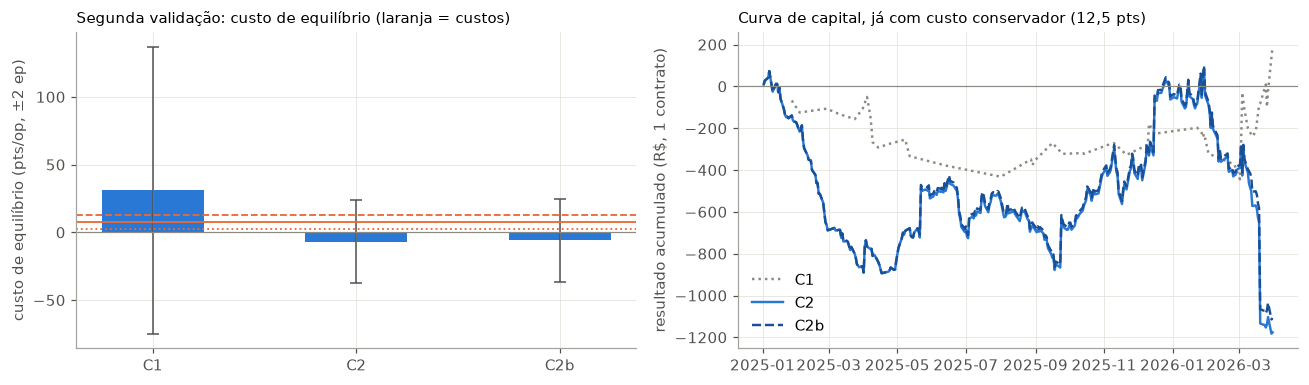

In [3]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.6))
ax = axs[0]
xs = np.arange(len(RES))
ax.bar(xs, RES.custo_equilibrio_pts, color=AZUL, width=0.5)
ax.errorbar(xs, RES.custo_equilibrio_pts, yerr=2 * RES.ep, fmt="none", color="#52514e", capsize=4, lw=1)
for nome, estilo in [("otimista", ":"), ("base", "-"), ("conservador", "--")]:
    ax.axhline(cu.CENARIOS[nome]["custo_pts"], color=LARANJA, lw=1.2, ls=estilo)
ax.axhline(0, color=CINZA, lw=0.8)
ax.set_xticks(xs, ["C1", "C2", "C2b"]); ax.set_ylabel("custo de equilíbrio (pts/op, ±2 ep)")
ax.set_title("Segunda validação: custo de equilíbrio (laranja = custos)", loc="left", fontsize=10)

ax = axs[1]
for ops, nome, cor, ls in [(ops_c1, "C1", CINZA, ":"), (ops_c2, "C2", AZUL, "-"), (ops_c2b, "C2b", "#184f95", "--")]:
    o = ops[ops.lado != 0]
    ax.plot(o.index, o.pontos.cumsum() * t.PONTO_WIN, color=cor, ls=ls, label=nome)
ax.axhline(0, color=CINZA, lw=0.8); ax.set_ylabel("resultado acumulado (R$, 1 contrato)")
ax.legend(frameon=False); ax.set_title("Curva de capital, já com custo conservador (12,5 pts)", loc="left", fontsize=10)
fig.tight_layout(); plt.show()

## Comparação com o desenvolvimento (descritivo)

O **mesmo código** aplicado ao período de desenvolvimento (até 2024). Deve reproduzir os Estudos 03 e 04 (C1 ≈ +44 ± 19, n = 221; C2 ≈ +29 ± 8, n = 903), o que também confere o código. **Nada aqui muda o veredito acima.**

In [4]:
_, DES = roda_candidatos(D_desenv)
desenv = DES[["custo_equilibrio_pts", "ep", "n_ops"]].rename(columns={"custo_equilibrio_pts": "custo_equilibrio_desenv_pts",
                                                                     "ep": "ep_desenv", "n_ops": "n_desenv"})
cmp_ = desenv.join(RES[["custo_equilibrio_pts", "ep", "n_ops"]].rename(columns={"custo_equilibrio_pts": "custo_equilibrio_valid_pts",
                                                                              "ep": "ep_valid", "n_ops": "n_valid"}))
cmp_.round(1)

,custo_equilibrio_desenv_pts,ep_desenv,n_desenv,custo_equilibrio_valid_pts,ep_valid,n_valid
candidato,,,,,,
C1 – gap grande,44.0,19.2,221,31.2,53.0,51
C2 – momentum no fechamento,29.1,7.8,901,-7.0,15.3,302
C2b – só pregões até 18:24,51.1,10.6,510,-6.0,15.4,300


In [5]:
# por trimestre (descritivo)
def por_trim(ops):
    o = ops[ops.lado != 0]
    return o.bruto.groupby(o.index.to_period("Q")).agg(n="size", custo_equilibrio="mean")
pd.concat({"C1": por_trim(ops_c1), "C2": por_trim(ops_c2), "C2b": por_trim(ops_c2b)}, axis=1).round(1)

C1                   C2                  C2b                 
         n custo_equilibrio   n custo_equilibrio   n custo_equilibrio
dia                                                                  
2025Q1   6            -77.5  59            -60.3  59            -60.3
2025Q2   9           -137.8  58             26.6  57             28.1
2025Q3   6             59.2  65             13.5  65             13.5
2025Q4  10             60.5  60             64.2  60             64.2
2026Q1  20            116.8  60            -80.2  59            -77.3

## Veredito

| Candidato | Custo de equilíbrio na validação | No desenvolvimento | Leitura estrita (oficial) | Leitura branda |
|---|---|---|---|---|
| C1 – gap grande | +31 ± 53 pts (n = 51) | +44 ± 19 (n = 221) | não passa | não passa |
| **C2 – momentum no fechamento** | **−7 ± 15 pts** (n = 302) | +29 ± 8 (n = 901) | **não passa** | não passa |
| C2b – só pregões até 18:24 | −6 ± 15 pts (n = 300) | +51 ± 11 (n = 510) | não passa | não passa |

**Nenhum candidato foi confirmado.** Pelo protocolo, nenhum segue para o teste final (abr–set/2026), que continua intocado.

**Leitura por candidato:**

- **C1:** **inconclusivo.** Só 51 operações em 15 meses, com erro-padrão de 53 pts. O resultado é compatível tanto com zero quanto com o efeito do desenvolvimento. Esta validação não tinha poder para dizer nada sobre ele.
- **C2:** **não é só falta de poder.**
  - A estimativa (−7 ± 15) fica **abaixo** da do desenvolvimento (+29 ± 8): a diferença é de 36 ± 17 pts (z ≈ 2,1).
  - O intervalo de 95% da validação, [−37; +23], **exclui** o valor do desenvolvimento.
  - Se o efeito verdadeiro fosse +29, a chance de observar −7 ou menos seria de ~1%.
  - Os dados de 2025–26 indicam que o efeito **não se manteve** no tamanho estimado. Um efeito menor e ainda lucrativo (entre 12,5 e 23 pts) não está descartado, mas também não há evidência dele.
- **C2b:** contraste ainda maior (+51 ± 11 → −6 ± 15; z ≈ 3,1). Além disso, desde 2024 o pregão vai **sempre** até 18:24 (a troca para 17:54 de março a novembro parou em 2023). O subgrupo "pregão até 18:24" do Estudo 04 misturava nov–mar de 2020–23 com o ano todo de 2024: o "regime" estava parcialmente confundido com o ano.
- **Por trimestre** (descritivo), o C2 oscila muito: −60, +27, +14, +64, −80 pts.

**Explicações possíveis** (não dá para separar com estes dados):

1. **O efeito existiu e desapareceu:** efeitos de microestrutura dependem de quem opera e de regras de mercado (horários, ajuste diário). O Estudo 04 mostrou que ele dependia do horário do pregão, um sinal de fragilidade.
2. **O efeito do desenvolvimento estava inflado:** mesmo vindo da literatura, olhamos variantes, subgrupos e horários antes de pré-registrar. Parte do z ≈ 4 pode ser seleção.
3. **Azar:** improvável para o C2 (~1%), dado o tamanho estimado no desenvolvimento.

**O que isso ensina:** um efeito com z ≈ 4, estável ano a ano, robusto à definição e apoiado na literatura **ainda assim** falhou fora da amostra. É exatamente para isso que existe a validação. Sem ela, o C2 seria apresentado como uma estratégia lucrativa.